In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd "/content/drive/MyDrive/ele680/final project"

/content/drive/MyDrive/ele680/final project


### Installation

#### Libraries

In [3]:
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.optim import AdamW
from torch.utils.data import DataLoader, WeightedRandomSampler

from datasets import load_from_disk
from transformers import (
AutoTokenizer,
AutoModelForSequenceClassification,
DataCollatorWithPadding,
get_linear_schedule_with_warmup
)

from sklearn.metrics import (
accuracy_score,
precision_score,
recall_score,
f1_score
)

from tqdm.auto import tqdm

print("Imports successful")

Imports successful


In [4]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


In [5]:
MODEL_NAME = "distilbert-base-uncased"

BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32

LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

NUM_EPOCHS = 3
WARMUP_RATIO = 0.1

# Group DRO step size
DRO_ETA = 0.01

NUM_TRAIN_GROUPS = 4

OUTPUT_DIR = Path("results/group_dro")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_DIR = OUTPUT_DIR / "best_model"
BEST_MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR.resolve())

Output directory: /content/drive/MyDrive/ele680/final project/results/group_dro


### Check GPU

In [6]:
import os
import json
import numpy as np
import pandas as pd

import torch
device = torch.device(
"cuda" if torch.cuda.is_available()
else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print(
        "WARNING: Group DRO training is running on CPU. "
        "Use the university GPU for the full experiment."
    )

PyTorch version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


In [7]:
train_dataset = load_from_disk(
"data/processed/tokenized_train"
)

val_dataset = load_from_disk(
"data/processed/tokenized_validation"
)

test_dataset = load_from_disk(
"data/processed/tokenized_test"
)

print(train_dataset)
print(val_dataset)
print(test_dataset)

print("\nSizes:")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Dataset({
    features: ['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 267516
})
Dataset({
    features: ['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 45047
})
Dataset({
    features: ['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'ins

In [8]:
IDENTITY_COLUMNS = [
"male",
"female",
"LGBTQ",
"christian",
"muslim",
"other_religions",
"black",
"white"
]

required_columns = [
"input_ids",
"attention_mask",
"label",
"identity_any"
] + IDENTITY_COLUMNS

for split_name, dataset in [
("Train", train_dataset),
("Validation", val_dataset),
("Test", test_dataset)]:
    missing = [
        col for col in required_columns
        if col not in dataset.column_names
    ]

    if missing:
        raise ValueError(
            f"{split_name} is missing columns: {missing}"
        )

print("All required columns are available.")

All required columns are available.


In [9]:
def add_training_group(example):
    identity_any = int(example["identity_any"])
    label = int(example["label"])

    # 0: identity=0, label=0
    # 1: identity=1, label=0
    # 2: identity=0, label=1
    # 3: identity=1, label=1

    group_id = identity_any + (2 * label)

    return {
        "group_id": group_id
    }

train_dataset = train_dataset.map(
    add_training_group,
    desc="Adding train group IDs"
)

val_dataset = val_dataset.map(
    add_training_group,
    desc="Adding validation group IDs"
)

test_dataset = test_dataset.map(
    add_training_group,
    desc="Adding test group IDs"
)

print("Group IDs added.")

Group IDs added.


In [10]:
GROUP_NAMES = {
0: "No identity, non-toxic",
1: "Identity, non-toxic",
2: "No identity, toxic",
3: "Identity, toxic"
}

group_check = pd.DataFrame({
"identity_any": train_dataset["identity_any"],
"label": train_dataset["label"],
"group_id": train_dataset["group_id"]
})

print(
group_check
.drop_duplicates()
.sort_values("group_id")
)

    identity_any  label  group_id
0              0      0         0
2              1      0         1
27             0      1         2
56             1      1         3


In [11]:
train_group_counts = (
pd.Series(train_dataset["group_id"])
.value_counts()
.sort_index()
)

group_distribution = pd.DataFrame({
"group_id": range(NUM_TRAIN_GROUPS),
"group_name": [
GROUP_NAMES[i]
for i in range(NUM_TRAIN_GROUPS)
],
"count": [
train_group_counts.get(i, 0)
for i in range(NUM_TRAIN_GROUPS)
]
})

group_distribution["percentage"] = (
group_distribution["count"]
/ group_distribution["count"].sum()
* 100
)

group_distribution


assert (
group_distribution["count"] > 0
).all(), "At least one Group DRO training group is empty."

print("All four training groups contain examples.")


All four training groups contain examples.


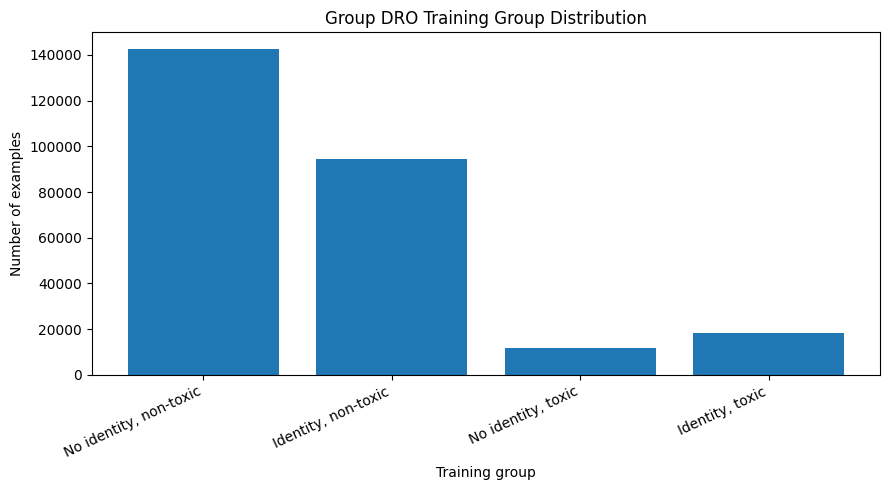

In [12]:
plt.figure(figsize=(9, 5))

plt.bar(
group_distribution["group_name"],
group_distribution["count"]
)

plt.title("Group DRO Training Group Distribution")
plt.xlabel("Training group")
plt.ylabel("Number of examples")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

In [13]:
tokenizer = AutoTokenizer.from_pretrained(
MODEL_NAME
)

padding_collator = DataCollatorWithPadding(
tokenizer=tokenizer,
return_tensors="pt"
)

print("Tokenizer and data collator loaded.")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer and data collator loaded.


In [14]:
def group_dro_collate(features):
    model_features = [
        {
            "input_ids": item["input_ids"],
            "attention_mask": item["attention_mask"]
        }
        for item in features
    ]

    padded = padding_collator(
        model_features
    )

    padded["labels"] = torch.tensor(
        [int(item["label"]) for item in features],
        dtype=torch.long
    )

    padded["group_id"] = torch.tensor(
        [int(item["group_id"]) for item in features],
        dtype=torch.long
    )

    padded["identity_any"] = torch.tensor(
        [int(item["identity_any"]) for item in features],
        dtype=torch.long
    )

    for identity in IDENTITY_COLUMNS:
        padded[identity] = torch.tensor(
            [int(item[identity]) for item in features],
            dtype=torch.long
        )

    if "uid" in features[0]:
        padded["uid"] = torch.tensor(
            [int(item["uid"]) for item in features],
            dtype=torch.long
        )

    return padded

In [15]:
train_group_ids = np.array(
train_dataset["group_id"]
)

group_counts = np.bincount(
train_group_ids,
minlength=NUM_TRAIN_GROUPS
)

print("Group counts:", group_counts)

Group counts: [142750  94423  11890  18453]


In [16]:
sample_weights = np.array([
1.0 / group_counts[group_id]
for group_id in train_group_ids
])

train_sampler = WeightedRandomSampler(
weights=torch.tensor(
sample_weights,
dtype=torch.double
),
num_samples=len(sample_weights),
replacement=True
)

print("Balanced sampler created.")

Balanced sampler created.


In [17]:
train_loader = DataLoader(
train_dataset,
batch_size=BATCH_SIZE,
sampler=train_sampler,
collate_fn=group_dro_collate,
pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
val_dataset,
batch_size=EVAL_BATCH_SIZE,
shuffle=False,
collate_fn=group_dro_collate,
pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
test_dataset,
batch_size=EVAL_BATCH_SIZE,
shuffle=False,
collate_fn=group_dro_collate,
pin_memory=torch.cuda.is_available()
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 16720
Validation batches: 1408
Test batches: 4148


In [18]:
batch = next(iter(train_loader))

for key, value in batch.items():
    print(key, value.shape)

input_ids torch.Size([16, 128])
attention_mask torch.Size([16, 128])
labels torch.Size([16])
group_id torch.Size([16])
identity_any torch.Size([16])
male torch.Size([16])
female torch.Size([16])
LGBTQ torch.Size([16])
christian torch.Size([16])
muslim torch.Size([16])
other_religions torch.Size([16])
black torch.Size([16])
white torch.Size([16])
uid torch.Size([16])


In [19]:
print("Labels:", batch["labels"][:10])
print("Groups:", batch["group_id"][:10])

Labels: tensor([1, 0, 0, 1, 1, 1, 0, 1, 1, 1])
Groups: tensor([2, 1, 0, 3, 3, 2, 1, 3, 3, 3])


In [20]:
model = AutoModelForSequenceClassification.from_pretrained(
MODEL_NAME,
num_labels=2
)

model = model.to(device)

print("Fresh model loaded:", MODEL_NAME)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Fresh model loaded: distilbert-base-uncased


In [21]:
optimizer = AdamW(
model.parameters(),
lr=LEARNING_RATE,
weight_decay=WEIGHT_DECAY
)

total_training_steps = (
len(train_loader)
* NUM_EPOCHS
)

warmup_steps = int(
WARMUP_RATIO
* total_training_steps
)

scheduler = get_linear_schedule_with_warmup(
optimizer,
num_warmup_steps=warmup_steps,
num_training_steps=total_training_steps
)

print("Total training steps:", total_training_steps)

Total training steps: 50160


In [22]:
loss_fn = nn.CrossEntropyLoss(
reduction="none"
)

print(loss_fn)

CrossEntropyLoss()


In [23]:
adv_probs = torch.ones(
NUM_TRAIN_GROUPS,
device=device
) / NUM_TRAIN_GROUPS

print("Initial adversarial weights:")
print(adv_probs)

Initial adversarial weights:
tensor([0.2500, 0.2500, 0.2500, 0.2500], device='cuda:0')


In [24]:
def calculate_official_group_metrics(labels, predictions, identity_data):
    rows = []
    labels = np.asarray(labels)
    predictions = np.asarray(predictions)

    for identity in IDENTITY_COLUMNS:
        identity_values = np.asarray(identity_data[identity])

        for label_value in [0, 1]:
            mask = (
                (identity_values == 1) &
                (labels == label_value)
            )
            n = int(mask.sum())

            if n == 0:
                accuracy = np.nan
            else:
                accuracy = accuracy_score(
                    labels[mask],
                    predictions[mask]
                )

            rows.append({
                "identity": identity,
                "label": label_value,
                "label_name": (
                    "non-toxic"
                    if label_value == 0
                    else "toxic"
                ),
                "n": n,
                "accuracy": accuracy
            })

    group_df = pd.DataFrame(rows)
    valid_groups = group_df.dropna(subset=["accuracy"])
    worst_group_accuracy = valid_groups["accuracy"].min()

    return group_df, worst_group_accuracy

In [25]:
def evaluate_model(model, data_loader, device):
    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []
    all_group_ids = []

    all_identity_data = {
        identity: []
        for identity in IDENTITY_COLUMNS
    }

    all_uids = []

    total_loss = 0.0
    total_examples = 0

    with torch.no_grad():
        for batch in tqdm(data_loader, desc="Evaluating", leave=False):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            logits = outputs.logits
            example_losses = loss_fn(logits, labels)
            probabilities = torch.softmax(logits, dim=1)
            predictions = torch.argmax(logits, dim=1)

            batch_size = labels.size(0)
            total_loss += example_losses.sum().item()
            total_examples += batch_size

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())
            all_group_ids.extend(batch["group_id"].numpy())

            for identity in IDENTITY_COLUMNS:
                all_identity_data[identity].extend(
                    batch[identity].numpy()
                )

            if "uid" in batch:
                all_uids.extend(batch["uid"].numpy())

    all_labels = np.asarray(all_labels)
    all_predictions = np.asarray(all_predictions)
    all_probabilities = np.asarray(all_probabilities)
    all_group_ids = np.asarray(all_group_ids)

    metrics = {
        "loss": total_loss / total_examples,
        "accuracy": accuracy_score(all_labels, all_predictions),
        "precision": precision_score(all_labels, all_predictions, zero_division=0),
        "recall": recall_score(all_labels, all_predictions, zero_division=0),
        "f1": f1_score(all_labels, all_predictions, zero_division=0)
    }

    official_group_df, worst_group_accuracy = calculate_official_group_metrics(
        all_labels,
        all_predictions,
        all_identity_data
    )

    metrics["worst_group_accuracy"] = worst_group_accuracy

    outputs_dict = {
        "labels": all_labels,
        "predictions": all_predictions,
        "probabilities": all_probabilities,
        "group_ids": all_group_ids,
        "identity_data": all_identity_data,
        "official_group_metrics": official_group_df
    }

    if all_uids:
        outputs_dict["uids"] = np.asarray(all_uids)

    return metrics, outputs_dict

In [26]:
def train_group_dro_epoch(
    model,
    data_loader,
    optimizer,
    scheduler,
    adv_probs,
    dro_eta,
    device
):
    model.train()

    running_robust_loss = 0.0
    running_examples = 0

    group_loss_sums = torch.zeros(NUM_TRAIN_GROUPS, device=device)
    group_counts_epoch = torch.zeros(NUM_TRAIN_GROUPS, device=device)

    progress_bar = tqdm(
        data_loader,
        desc="Group DRO training"
    )

    for batch in progress_bar:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)
        group_ids = batch["group_id"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        logits = outputs.logits
        example_losses = loss_fn(logits, labels)

        group_losses = torch.zeros(NUM_TRAIN_GROUPS, device=device)
        group_present = torch.zeros(NUM_TRAIN_GROUPS, dtype=torch.bool, device=device)

        for group_id in range(NUM_TRAIN_GROUPS):
            mask = group_ids == group_id
            if mask.any():
                group_present[group_id] = True
                group_losses[group_id] = example_losses[mask].mean()
                group_loss_sums[group_id] += example_losses[mask].detach().sum()
                group_counts_epoch[group_id] += mask.sum()

        # Update adversarial group weights.
        # High-loss groups receive increasing weight.
        with torch.no_grad():
            adv_probs[group_present] *= torch.exp(
                dro_eta * group_losses[group_present].detach()
            )
            adv_probs /= adv_probs.sum()

        # Only groups represented in this batch contribute to the current robust loss.
        present_weights = adv_probs[group_present]
        present_weights = present_weights / present_weights.sum()

        robust_loss = torch.sum(present_weights * group_losses[group_present])

        robust_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

        batch_size = labels.size(0)
        running_robust_loss += robust_loss.item() * batch_size
        running_examples += batch_size

        progress_bar.set_postfix({
            "robust_loss": f"{robust_loss.item():.4f}"
        })

    epoch_group_losses = group_loss_sums / group_counts_epoch.clamp(min=1)
    mean_robust_loss = running_robust_loss / running_examples

    return mean_robust_loss, epoch_group_losses.detach().cpu(), adv_probs.detach().cpu()

In [27]:
training_history = []
best_worst_group_accuracy = -np.inf
best_epoch = None

for epoch in range(1, NUM_EPOCHS + 1):
    print("\n" + "=" * 70)
    print(f"EPOCH {epoch}/{NUM_EPOCHS}")
    print("=" * 70)

    train_robust_loss, epoch_group_losses, current_adv_probs = train_group_dro_epoch(
        model=model,
        data_loader=train_loader,
        optimizer=optimizer,
        scheduler=scheduler,
        adv_probs=adv_probs,
        dro_eta=DRO_ETA,
        device=device
    )

    print(f"\nTrain robust loss: {train_robust_loss:.4f}")
    print("\nTraining group losses:")
    for group_id in range(NUM_TRAIN_GROUPS):
        print(f"  Group {group_id} ({GROUP_NAMES[group_id]}): {epoch_group_losses[group_id]:.4f}")

    print("\nAdversarial group weights:")
    for group_id in range(NUM_TRAIN_GROUPS):
        print(f"  Group {group_id} ({GROUP_NAMES[group_id]}): {current_adv_probs[group_id]:.4f}")

    val_metrics, val_outputs = evaluate_model(
        model=model,
        data_loader=val_loader,
        device=device
    )

    print("\nValidation results:")
    for metric_name, metric_value in val_metrics.items():
        print(f"  {metric_name}: {metric_value:.4f}")

    history_row = {
        "epoch": epoch,
        "train_robust_loss": train_robust_loss,
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "val_f1": val_metrics["f1"],
        "val_worst_group_accuracy": val_metrics["worst_group_accuracy"]
    }

    for group_id in range(NUM_TRAIN_GROUPS):
        history_row[f"group_{group_id}_loss"] = float(epoch_group_losses[group_id])
        history_row[f"group_{group_id}_weight"] = float(current_adv_probs[group_id])

    training_history.append(history_row)

    current_worst = val_metrics["worst_group_accuracy"]
    if current_worst > best_worst_group_accuracy:
        best_worst_group_accuracy = current_worst
        best_epoch = epoch

        model.save_pretrained(BEST_MODEL_DIR)
        tokenizer.save_pretrained(BEST_MODEL_DIR)

        val_outputs["official_group_metrics"].to_csv(
            OUTPUT_DIR / "best_validation_group_metrics.csv",
            index=False
        )
        print(f"\nSaved new best model from epoch {epoch}.")


EPOCH 1/3


Group DRO training:   0%|          | 0/16720 [00:00<?, ?it/s]


Train robust loss: 0.3986

Training group losses:
  Group 0 (No identity, non-toxic): 0.3066
  Group 1 (Identity, non-toxic): 0.4030
  Group 2 (No identity, toxic): 0.3839
  Group 3 (Identity, toxic): 0.4045

Adversarial group weights:
  Group 0 (No identity, non-toxic): 0.0000
  Group 1 (Identity, non-toxic): 0.6016
  Group 2 (No identity, toxic): 0.0241
  Group 3 (Identity, toxic): 0.3743


Evaluating:   0%|          | 0/1408 [00:00<?, ?it/s]


Validation results:
  loss: 0.3443
  accuracy: 0.8678
  precision: 0.4478
  recall: 0.7833
  f1: 0.5698
  worst_group_accuracy: 0.6120


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Group DRO training:   0%|          | 0/16720 [00:00<?, ?it/s]


Train robust loss: 0.1694

Training group losses:
  Group 0 (No identity, non-toxic): 0.1805
  Group 1 (Identity, non-toxic): 0.1450
  Group 2 (No identity, toxic): 0.1663
  Group 3 (Identity, toxic): 0.1522

Adversarial group weights:
  Group 0 (No identity, non-toxic): 0.8805
  Group 1 (Identity, non-toxic): 0.0086
  Group 2 (No identity, toxic): 0.1007
  Group 3 (Identity, toxic): 0.0102


Evaluating:   0%|          | 0/1408 [00:00<?, ?it/s]


Validation results:
  loss: 0.3972
  accuracy: 0.8985
  precision: 0.5346
  recall: 0.7058
  f1: 0.6084
  worst_group_accuracy: 0.5286


In [28]:
history_df = pd.DataFrame(training_history)
history_df


history_df.to_csv(OUTPUT_DIR / "training_history.csv",index=False)
print("Training history saved.")

Training history saved.


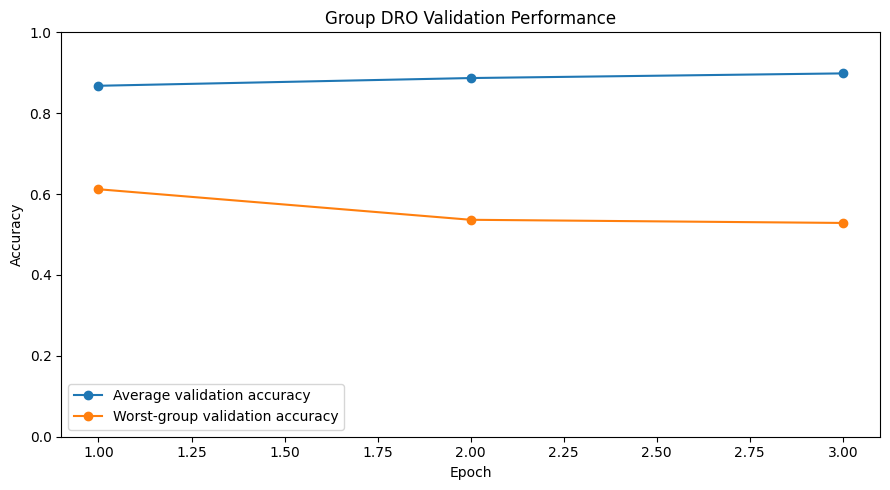

In [29]:
plt.figure(figsize=(9, 5))

plt.plot(
history_df["epoch"],
history_df["val_accuracy"],
marker="o",
label="Average validation accuracy"
)

plt.plot(
history_df["epoch"],
history_df[
"val_worst_group_accuracy"
],
marker="o",
label="Worst-group validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Group DRO Validation Performance")
plt.ylim(0, 1)
plt.legend()

plt.tight_layout()
plt.show()


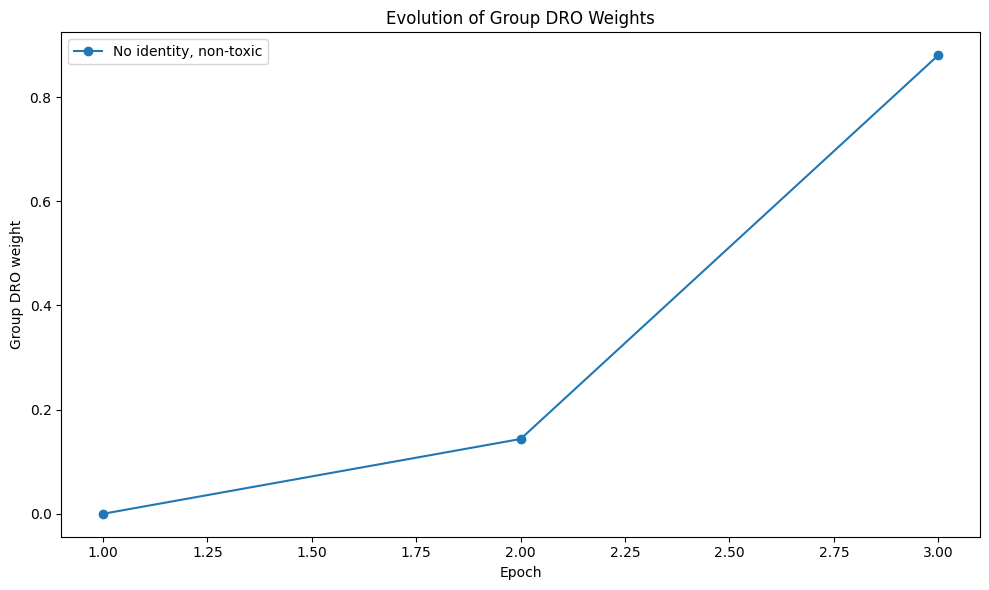

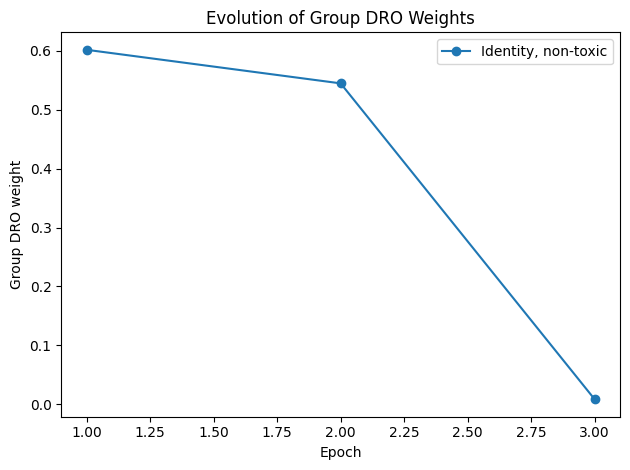

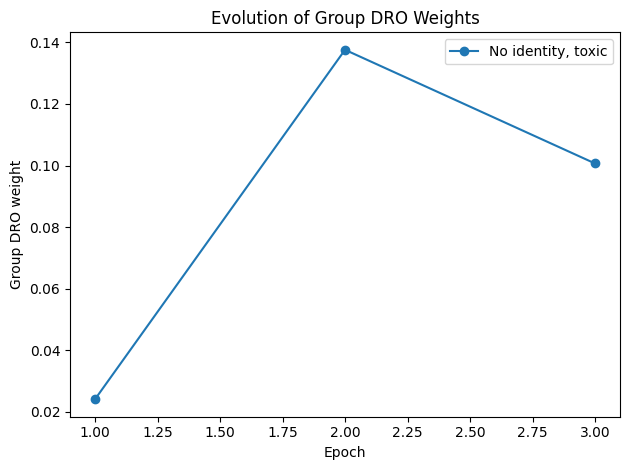

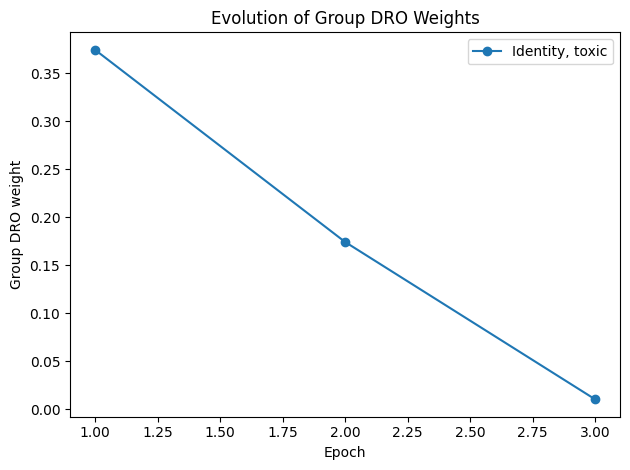

In [30]:
plt.figure(figsize=(10, 6))
for group_id in range(NUM_TRAIN_GROUPS):
  plt.plot(history_df["epoch"],history_df[f"group_{group_id}_weight"],marker="o",label=GROUP_NAMES[group_id])
  plt.xlabel("Epoch")
  plt.ylabel("Group DRO weight")
  plt.title("Evolution of Group DRO Weights")
  plt.legend()
  plt.tight_layout()
  plt.show()

In [31]:
print("Best epoch:", best_epoch)
print("Best validation worst-group accuracy:",best_worst_group_accuracy)

best_model = (AutoModelForSequenceClassification.from_pretrained(BEST_MODEL_DIR))
best_model = best_model.to(device)
print("Best model loaded.")

Best epoch: 1
Best validation worst-group accuracy: 0.6119791666666666


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Best model loaded.


In [32]:
test_metrics, test_outputs = evaluate_model(model=best_model,data_loader=test_loader,device=device)
print("Final Group DRO test metrics:")

for metric_name, metric_value in (test_metrics.items()):
  print(f"{metric_name}: "f"{metric_value:.4f}")

Evaluating:   0%|          | 0/4148 [00:00<?, ?it/s]

Final Group DRO test metrics:
loss: 0.3505
accuracy: 0.8647
precision: 0.4461
recall: 0.7853
f1: 0.5690
worst_group_accuracy: 0.6356


In [33]:
test_group_metrics = test_outputs["official_group_metrics"]
test_group_metrics.sort_values("accuracy")
worst_group_row = (test_group_metrics.dropna(subset=["accuracy"]).sort_values("accuracy").iloc[0])

print("Worst Group DRO test group:")
print(worst_group_row)

Worst Group DRO test group:
identity      christian
label                 1
label_name        toxic
n                  1254
accuracy       0.635566
Name: 7, dtype: object


In [34]:
prediction_df = test_dataset.to_pandas()

prediction_df["true_label"] = (
test_outputs["labels"]
)

prediction_df["prediction"] = (
test_outputs["predictions"]
)

prediction_df["prob_non_toxic"] = (
test_outputs["probabilities"][:, 0]
)

prediction_df["prob_toxic"] = (
test_outputs["probabilities"][:, 1]
)

prediction_df["group_id"] = (
test_outputs["group_ids"]
)

print(prediction_df.shape)
print(prediction_df.columns.tolist())

(132730, 30)
['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label', 'input_ids', 'token_type_ids', 'attention_mask', 'group_id', 'true_label', 'prediction', 'prob_non_toxic', 'prob_toxic']


In [35]:
prediction_path = (OUTPUT_DIR / "test_predictions.csv")

prediction_df.to_csv(prediction_path,index=False)

print("Predictions saved to:",prediction_path.resolve())

Predictions saved to: /content/drive/MyDrive/ele680/final project/results/group_dro/test_predictions.csv


In [36]:
serializable_test_metrics = {key: float(value) for key, value in test_metrics.items()}

In [37]:
with open(OUTPUT_DIR / "test_metrics.json","w",encoding="utf-8") as file:
  json.dump(serializable_test_metrics,file,indent=4)
  test_group_metrics.to_csv(OUTPUT_DIR / "test_group_metrics.csv",index=False)
  print("Test metrics saved.")

Test metrics saved.


In [38]:
experiment_config = {
"algorithm": "Group DRO",
"model_name": MODEL_NAME,
"training_group_definition":
"identity_any crossed with toxicity label",
"evaluation_group_definition":
"each positive WILDS identity crossed with label",
"identity_columns":
IDENTITY_COLUMNS,
"batch_size": BATCH_SIZE,
"eval_batch_size":
EVAL_BATCH_SIZE,
"learning_rate":
LEARNING_RATE,
"weight_decay":
WEIGHT_DECAY,
"epochs":
NUM_EPOCHS,
"warmup_ratio":
WARMUP_RATIO,
"dro_eta":
DRO_ETA,
"seed":
SEED,
"best_epoch":
best_epoch,
"best_validation_worst_group_accuracy":
float(best_worst_group_accuracy)}



with open(OUTPUT_DIR / "experiment_config.json","w",encoding="utf-8") as file:
  json.dump(experiment_config,file,indent=4)
  print("Experiment configuration saved.")

Experiment configuration saved.


In [39]:
print("Generated files:")

for path in sorted(OUTPUT_DIR.rglob("*")):
  if path.is_file():
    print(path)

Generated files:
results/group_dro/best_model/config.json
results/group_dro/best_model/model.safetensors
results/group_dro/best_model/tokenizer.json
results/group_dro/best_model/tokenizer_config.json
results/group_dro/best_validation_group_metrics.csv
results/group_dro/experiment_config.json
results/group_dro/test_group_metrics.csv
results/group_dro/test_metrics.json
results/group_dro/test_predictions.csv
results/group_dro/training_history.csv
